## Tại đây chúng ta sẽ sử dụng thư viện chung

In [1]:
import numpy as np # linear algebra
import pandas as pd # data processing,
import matplotlib.pyplot as plt   # data visualization
import seaborn as sns             # statistical data visualization
import statsmodels.api as sm
import plotly.express as px
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import acf, pacf
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.seasonal import seasonal_decompose, STL
from statsmodels.stats.diagnostic import acorr_ljungbox

## Data Processing

In [2]:
df = pd.read_csv("H:\\HK1_2026-2027\\Times Series\\Chapter2_Solved\\daily-min-temperatures.csv")

In [3]:
df[df.columns[0:2]]

,Date,Temp
0,1981-01-01,20.7
1,1981-01-02,17.9
2,1981-01-03,18.8
3,1981-01-04,14.6
4,1981-01-05,15.8
...,...,...
3645,1990-12-27,14.0
3646,1990-12-28,13.6
3647,1990-12-29,13.5
3648,1990-12-30,15.7


In [4]:
df['Date'] = pd.to_datetime(df['Date'])

In [5]:
df = df.set_index('Date') # Chuyển sang lấy cột Date làm cột chính

In [6]:
df = df.asfreq('D') # Vì là dữ liệu theo ngày nên set 'D' hay Day

In [7]:
df['Temp'] = df['Temp'].interpolate()

In [8]:
df

,Temp
Date,
1981-01-01,20.7
1981-01-02,17.9
1981-01-03,18.8
1981-01-04,14.6
1981-01-05,15.8
...,...
1990-12-27,14.0
1990-12-28,13.6
1990-12-29,13.5


## Bài tập 1

### Tải và xem trước dữ liệu

            Temp
Date            
1981-01-01  20.7
1981-01-02  17.9
1981-01-03  18.8
1981-01-04  14.6
1981-01-05  15.8
1981-01-06  15.8
1981-01-07  15.8
1981-01-08  17.4
1981-01-09  21.8
1981-01-10  20.0
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 3652 entries, 1981-01-01 to 1990-12-31
Freq: D
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Temp    3652 non-null   float64
dtypes: float64(1)
memory usage: 57.1 KB
None
              Temp
count  3652.000000
mean     11.179587
std       4.071482
min       0.000000
25%       8.300000
50%      11.000000
75%      14.000000
max      26.300000
Missing: {'Temp': 0}


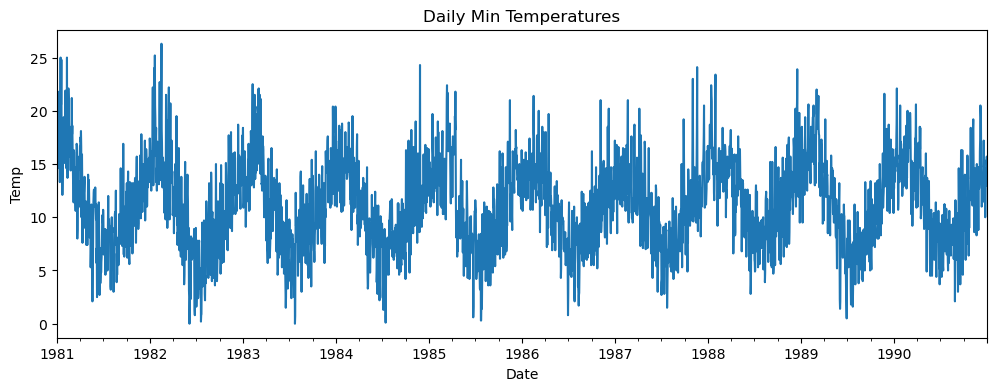

In [9]:
# Nhớ kiểm tra  (head, info, plot).
print(df.head(10))
print(df.info())
print(df.describe())
print("Missing:", df.isna().sum().to_dict())


df['Temp'].plot(figsize=(12, 4), title="Daily Min Temperatures")
plt.xlabel("Date"); plt.ylabel("Temp"); plt.show()

### Tính ACF, PACF đến 40 lags

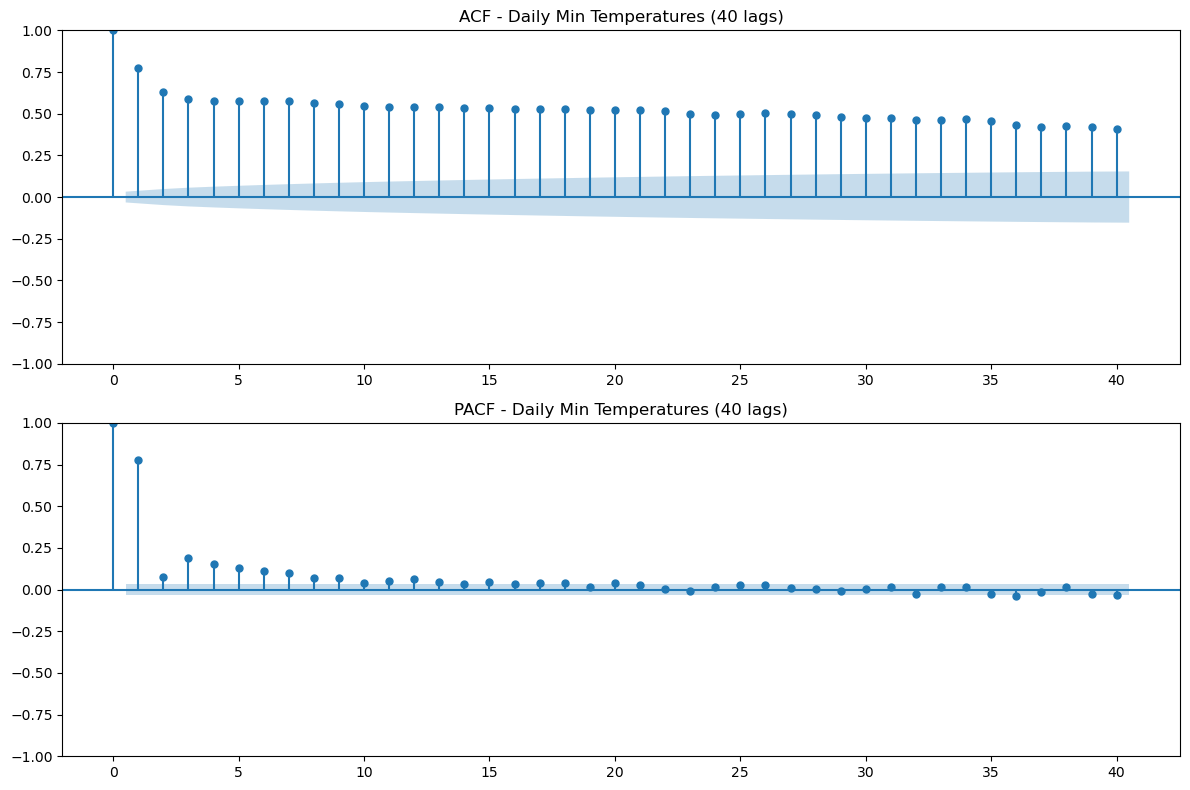

ACF: [1.     0.7744 0.6304 0.5854 0.578  0.5774 0.5755 0.5745 0.5671 0.5607
 0.547  0.5389 0.5413 0.5423 0.5358 0.5337 0.5308 0.5298 0.5309 0.5243
 0.523  0.5221 0.5134 0.498  0.4938 0.5003 0.5053 0.5002 0.4912 0.4804
 0.4742 0.4763 0.4646 0.4626 0.466  0.4546 0.4323 0.4219 0.4285 0.4222
 0.4075]
PACF: [ 1.      0.7746  0.0769  0.1894  0.1526  0.1295  0.1104  0.1023  0.0727
  0.0711  0.0371  0.0492  0.0615  0.048   0.0317  0.0467  0.0331  0.0401
  0.0413  0.0174  0.0374  0.0272  0.0061 -0.0092  0.0171  0.0307  0.0264
  0.007   0.0048 -0.0056  0.0022  0.0187 -0.026   0.0141  0.0138 -0.0243
 -0.0408 -0.0131  0.0139 -0.028  -0.0309]


In [10]:
# Code tại đây

fig, axes = plt.subplots(2, 1, figsize=(12, 8))
plot_acf(df['Temp'], lags=40, ax=axes[0])
axes[0].set_title("ACF - Daily Min Temperatures (40 lags)")
plot_pacf(df['Temp'], lags=40, ax=axes[1])
axes[1].set_title("PACF - Daily Min Temperatures (40 lags)")
plt.tight_layout(); plt.show()

print("ACF:", acf(df['Temp'], nlags=40, fft=True).round(4))
print("PACF:", pacf(df['Temp'], nlags=40).round(4))

### Kết luận
Kết luận
1. Tự tương quan mạnh? Có. ACF lag1 = 0.77, toàn bộ 40 lag đều có ý nghĩa thống kê. Chuỗi có "trí nhớ" ngắn hạn rất tốt — giá trị hôm nay phụ thuộc mạnh vào hôm qua.
2. Xu hướng / mùa vụ?  ACF giảm chậm → trend / non-stationary. Đây đúng là trường hợp này (0.77 → 0.41 sau 40 lag, giảm rất chậm). Không thấy mùa vụ trong cửa sổ 40 lag: không có đỉnh lặp lại rõ (lag7 ≈ 0.574 ngang bằng lân cận, không phải peak). Mùa vụ năm (lag 365) nằm ngoài phạm vi 40 lag nên chưa kiểm tra được. nhưng khi chạy thử lag 365 thì AFC có đỉnh theo chu kì-> đây là pattern chuẩn của nhiệt độ ngày theo mùa.
3. Lag quan trọng nhất? Lag1 (cả ACF và PACF đều ~0.77). PACF "cắt" mạnh sau lag1 với vài lag nhỏ tiếp theo (2–9)


## Bài tập 2


### 1. Sinh dữ liệu white noise bằng NumPy (1000 điểm)


Số điểm: 1000
Trung bình: 0.019 | Độ lệch chuẩn: 0.979


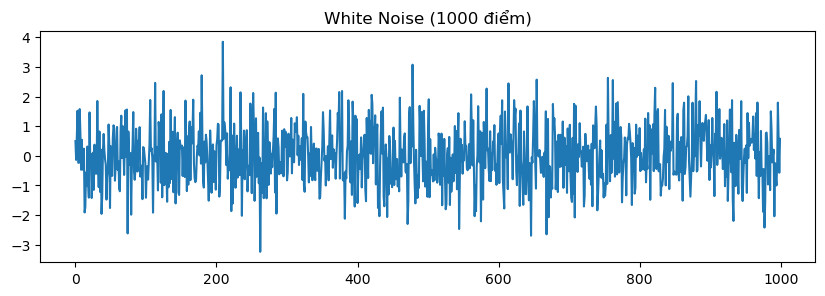

In [11]:
np.random.seed(42)
wn = np.random.normal(loc=0, scale=1, size=1000)

print("Số điểm:", len(wn))
print("Trung bình:", round(wn.mean(), 3), "| Độ lệch chuẩn:", round(wn.std(), 3))

plt.figure(figsize=(10, 3))
plt.plot(wn)
plt.title("White Noise (1000 điểm)")
plt.show()

### 2. Vẽ ACF -> kiểm tra xem các lag có nằm trong ngưỡng tin cậy 95% không


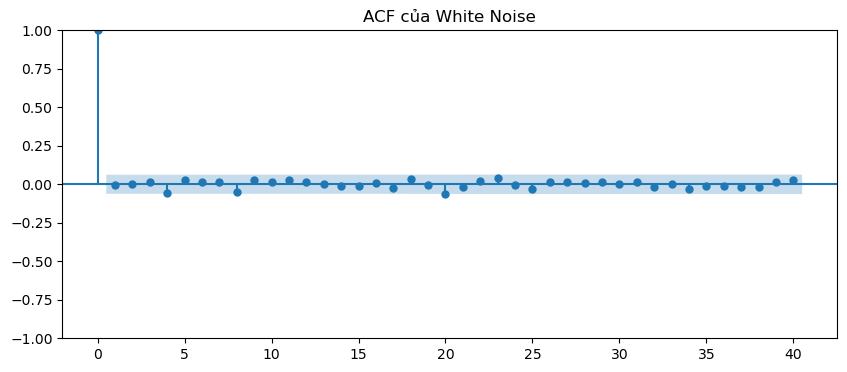

Ngưỡng tin cậy 95%: ±0.062
Số lag vượt ngưỡng: 1/40


In [12]:
fig, ax = plt.subplots(figsize=(10, 4))
plot_acf(wn, lags=40, alpha=0.05, ax=ax)
ax.set_title("ACF của White Noise")
plt.show()

vals = acf(wn, nlags=40)[1:]          # bỏ lag 0 (luôn bằng 1)
bound = 1.96 / np.sqrt(len(wn))
so_lag_vuot = np.sum(np.abs(vals) > bound)
print(f"Ngưỡng tin cậy 95%: ±{bound:.3f}")
print(f"Số lag vượt ngưỡng: {so_lag_vuot}/40")

### 3. So sánh ACF của white noise với ACF của chuỗi AirPassengers


Số điểm AirPassengers: 144


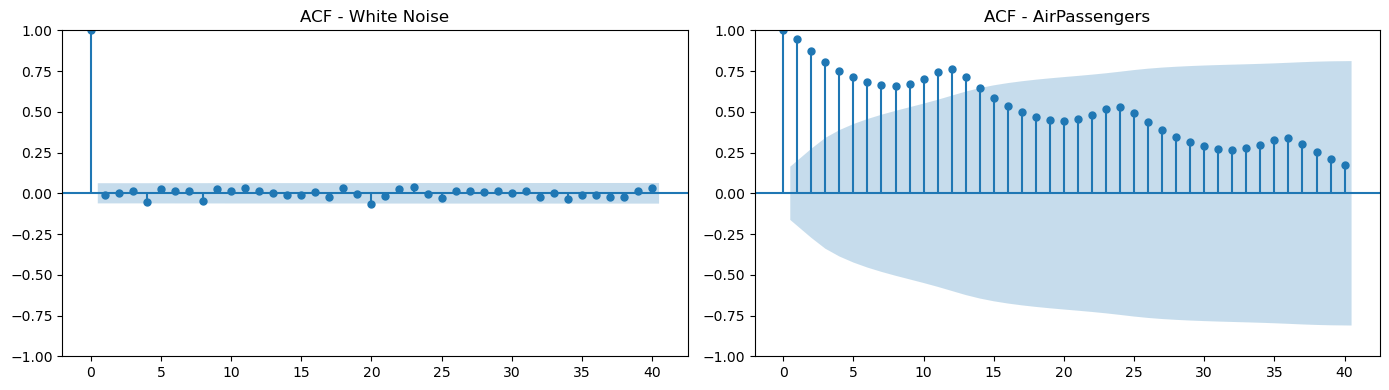

In [13]:
# Tải AirPassengers (cần internet, Colab có sẵn)
ap = sm.datasets.get_rdataset("AirPassengers").data["value"]
print("Số điểm AirPassengers:", len(ap))   # kỳ vọng: 144

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(wn, lags=40, ax=axes[0]); axes[0].set_title("ACF - White Noise")
plot_acf(ap, lags=40, ax=axes[1]); axes[1].set_title("ACF - AirPassengers")
plt.tight_layout()
plt.show()

### 4. Viết 5 dòng mô tả sự khác nhau

In [14]:
# 1. White noise chỉ có 1/40 lag vượt ngưỡng tin cậy 95% (±0.062), phần còn lại nằm trong dải tin cậy. ACF của AirPassengers có các lag đầu nằm hẳn ngoài dải tin cậy.

# 2. ACF của white noise dao động ngẫu nhiên quanh 0 và không theo quy luật nào. ACF của AirPassengers bắt đầu rất cao (gần 0.95 ở lag 1), giảm rất chậm và vẫn dương qua 40 lag.

# 3. White noise không có xu hướng, còn ACF giảm chậm của AirPassengers cho thấy chuỗi có xu hướng tăng dài hạn, tức là chuỗi không dừng.

# 4. AirPassengers có gợn nhẹ quanh lag 12 và 24 (tính mùa vụ theo năm), trong khi ACF của white noise không có chu kỳ nào.

# 5. White noise gồm các giá trị độc lập nên không thể dự báo từ quá khứ. AirPassengers có tự tương quan mạnh nên có thể mô hình hóa và dự báo.

## Bài tập 3

### 1. Chọn chuỗi dữ liệu theo tháng hoặc theo quý


In [15]:
# Code tại đây
monthly = df['Temp'].resample('MS').mean()  # MS = Month Start
print(monthly.shape)
monthly.head()

(120,)


Date
1981-01-01    17.712903
1981-02-01    17.678571
1981-03-01    13.500000
1981-04-01    12.356667
1981-05-01     9.490323
Freq: MS, Name: Temp, dtype: float64

### 2. Dùng phương pháp STL hoặc classical decomposition


In [16]:
# Code tại đây
### 2. Dùng STL decomposition (chu kỳ mùa vụ = 12 tháng)

stl = STL(monthly, period=12, robust=True)
result = stl.fit()

### 3. Vẽ 4 thành phần: Observed, Trend, Seasonal, Residual


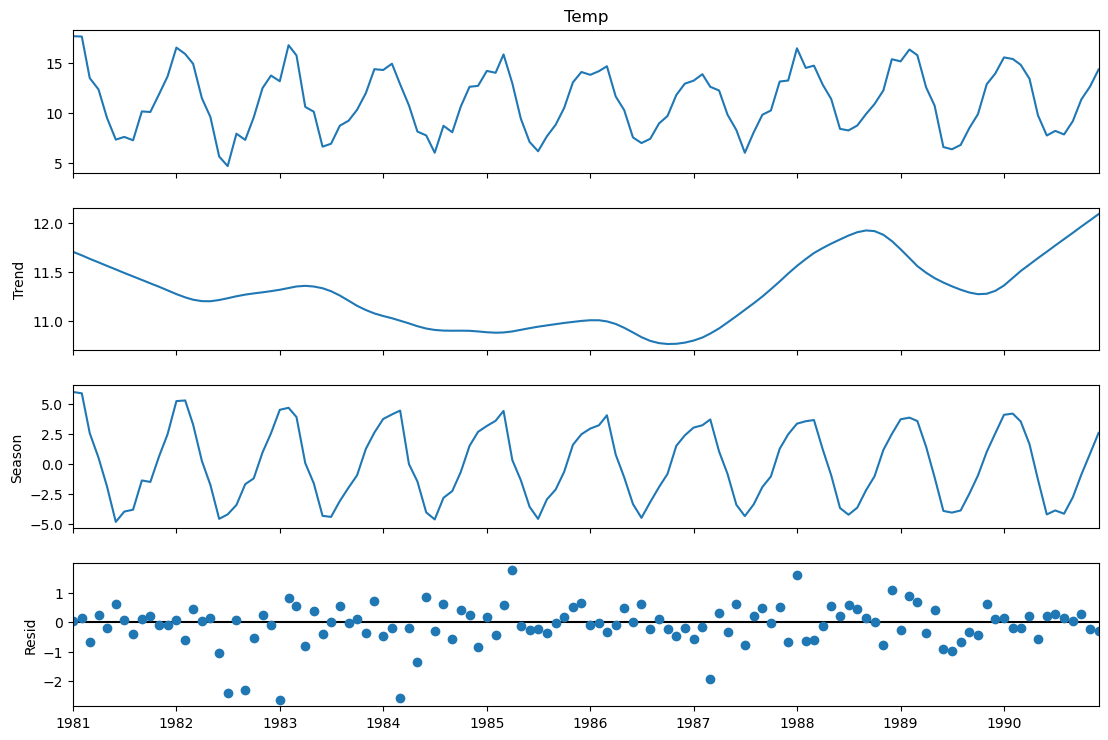

In [17]:
# Code tại đây
fig = result.plot()
fig.set_size_inches(12, 8)
plt.show()

### 4. Mô tả

Trend đầu chuỗi: 11.71 | cuối chuỗi: 12.09
Độ dốc: 0.0032 °C/tháng (~0.39 °C sau 10 năm)

Độ mạnh mùa vụ Fs = 0.950 (càng gần 1 càng mạnh)
Date
1     3.96
2     4.14
3     3.70
4     0.71
5    -1.35
6    -3.99
7    -4.28
8    -3.44
9    -2.08
10   -0.98
11    1.16
12    2.51
Name: season, dtype: float64

Mean residual: -0.0886 | Std: 0.6965


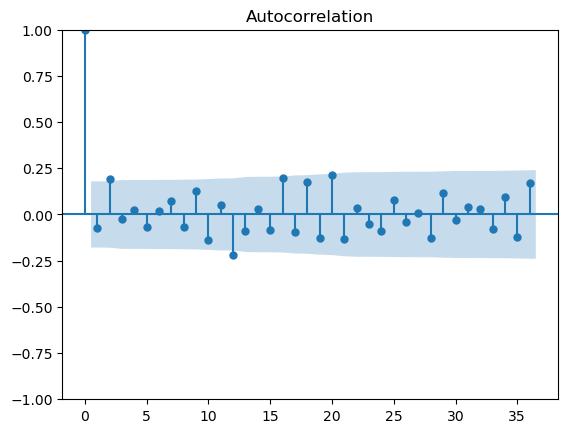

      lb_stat  lb_pvalue
12  18.787951   0.093776
24  45.513974   0.005062


In [18]:
# Code tại đây
trend, seasonal, resid = result.trend, result.seasonal, result.resid

# --- Xu hướng tăng hay giảm? ---
slope = np.polyfit(np.arange(len(trend)), trend.values, 1)[0]
print(f"Trend đầu chuỗi: {trend.iloc[0]:.2f} | cuối chuỗi: {trend.iloc[-1]:.2f}")
print(f"Độ dốc: {slope:.4f} °C/tháng (~{slope*120:.2f} °C sau 10 năm)")

# --- Mùa vụ mạnh hay yếu? ---
Fs = max(0, 1 - resid.var() / (resid + seasonal).var())
print(f"\nĐộ mạnh mùa vụ Fs = {Fs:.3f} (càng gần 1 càng mạnh)")
print(seasonal.groupby(seasonal.index.month).mean().round(2))

# --- Residual có giống white noise không? ---
print("\nMean residual:", round(resid.mean(), 4), "| Std:", round(resid.std(), 4))
plot_acf(resid, lags=36)
plt.show()

print(acorr_ljungbox(resid, lags=[12, 24], return_df=True))

#### Nhận xét

- **Xu hướng:** Thành phần Trend tăng rất nhẹ, từ 11.71°C lên 12.09°C (độ dốc ≈ 0.0032°C/tháng,
  khoảng +0.39°C sau 10 năm). Mức thay đổi nhỏ so với biên độ mùa vụ nên có thể xem chuỗi
  gần như ổn định về mức trung bình, không có xu hướng tăng/giảm rõ rệt.

- **Mùa vụ:** Rất mạnh (Fs = 0.950). Thành phần Seasonal dao động khoảng ±4°C, lặp lại đều
  theo chu kỳ 12 tháng: nhiệt độ cao nhất vào tháng 1–3 (cao nhất tháng 2: +4.14) và thấp nhất
  vào tháng 6–8 (thấp nhất tháng 7: −4.28), phù hợp với khí hậu mùa hè/đông ở Nam bán cầu.
  Biên độ mùa vụ không đổi nhiều theo mức của chuỗi nên dùng mô hình phân rã cộng (additive).

- **Residual:** Dao động quanh 0 (mean = −0.09, std = 0.70), nhỏ hơn nhiều so với biên độ mùa vụ.
  Biểu đồ ACF cho thấy phần lớn các lag nằm trong khoảng tin cậy 95%, riêng lag 12 vượt ra ngoài.
  Kiểm định Ljung-Box cho p = 0.094 ở lag 12 nhưng p = 0.005 ở lag 24. Vì vậy residual
  gần giống white noise nhưng chưa hoàn toàn: vẫn còn một chút tự tương quan còn sót lại,
  có thể do cấu trúc mùa vụ chưa được tách hết.

- **Kết luận:** STL đã tách tốt phần lớn cấu trúc của chuỗi (trend + mùa vụ giải thích gần như
  toàn bộ biến động). Chuỗi có mùa vụ rõ nên phù hợp để dự báo bằng mô hình có thành phần mùa vụ như SARIMA.
  

## Bài tập 4

### 1. Tạo dữ liệu thiếu (NaN) giả lập hoặc dùng dataset có missing


In [19]:
df = pd.read_csv('daily-min-temperatures.csv', parse_dates=['Date'], index_col='Date')
series = df['Temp']

np.random.seed(42)
ts_missing = series.copy()
idx = np.random.choice(len(ts_missing), size=int(0.05*len(ts_missing)), replace=False)
ts_missing.iloc[idx] = np.nan
ts_missing.iloc[1000:1010] = np.nan

### 2. Kiểm tra missing: isna().sum()


In [20]:
print(ts_missing.isna().sum())

191


### 3. Xử lý missing bằng 2 cách: Forward-fill và Interpolation


In [21]:
ts_ffill = ts_missing.ffill()
ts_interp = ts_missing.interpolate(method='time')

### 4. Phát hiện outliers bằng: Rolling mean/variance; Z-score hoặc IQR


In [22]:
roll_mean = ts_interp.rolling(30, center=True).mean()
roll_std = ts_interp.rolling(30, center=True).std()
out_roll = (ts_interp - roll_mean).abs() > 3 * roll_std

z = (ts_interp - ts_interp.mean()) / ts_interp.std()
out_z = z.abs() > 3

Q1, Q3 = ts_interp.quantile(0.25), ts_interp.quantile(0.75)
IQR = Q3 - Q1
out_iqr = (ts_interp < Q1 - 1.5*IQR) | (ts_interp > Q3 + 1.5*IQR)

print(out_roll.sum(), out_z.sum(), out_iqr.sum())

4 8 14


### 5. Vẽ trước và sau khi xử lý

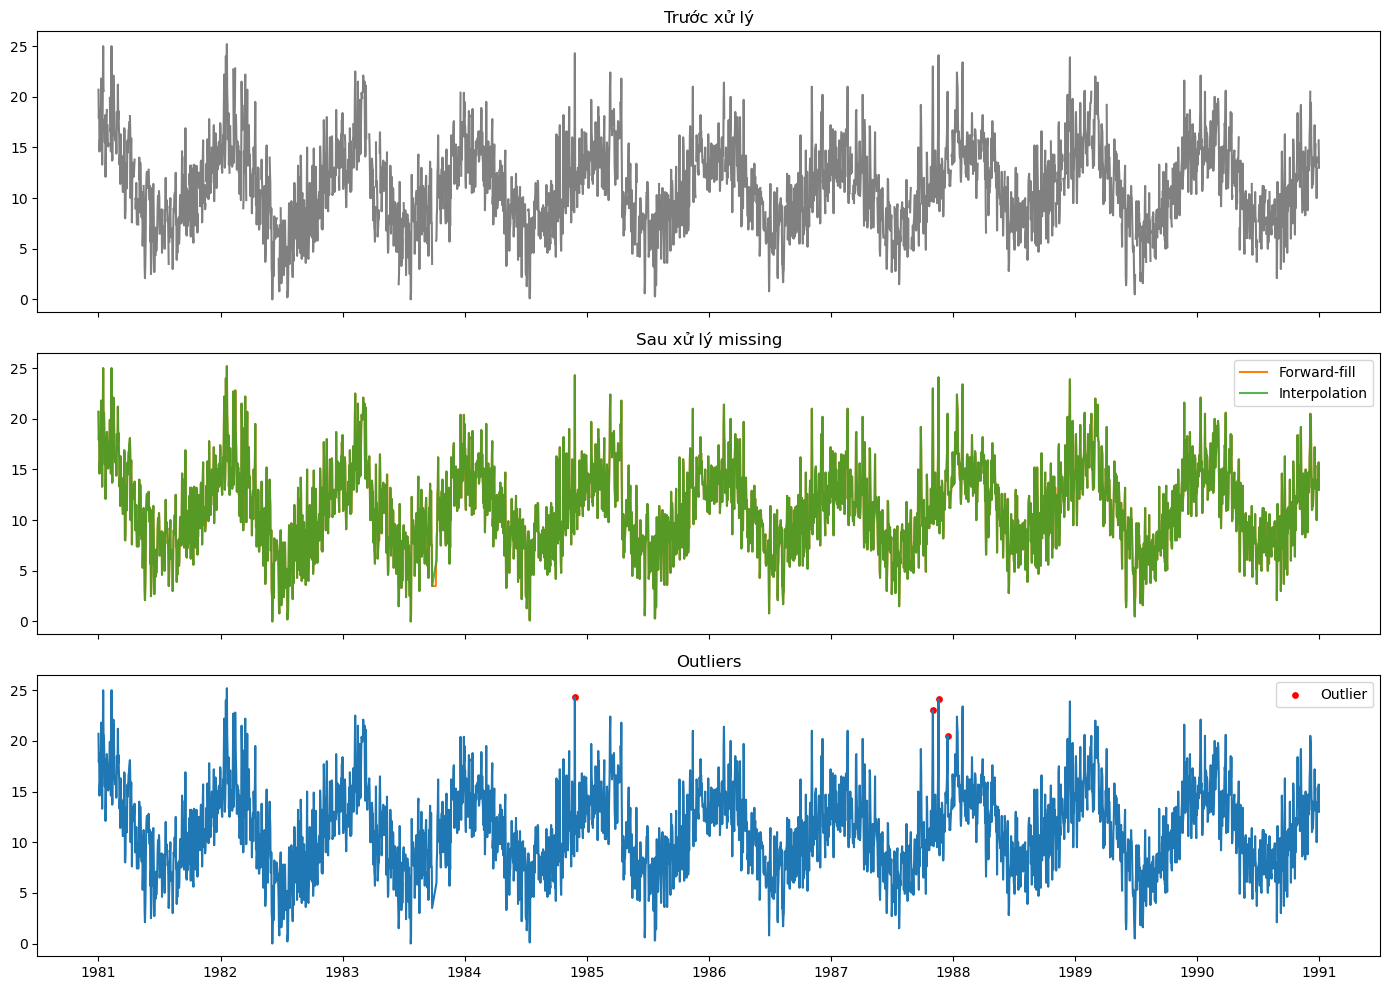

In [23]:
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)

axes[0].plot(ts_missing, color='gray')
axes[0].set_title('Trước xử lý')

axes[1].plot(ts_ffill, color='tab:orange', label='Forward-fill')
axes[1].plot(ts_interp, color='tab:green', alpha=0.8, label='Interpolation')
axes[1].set_title('Sau xử lý missing')
axes[1].legend()

axes[2].plot(ts_interp, color='tab:blue')
axes[2].scatter(ts_interp.index[out_roll], ts_interp[out_roll], color='red', s=15, label='Outlier')
axes[2].set_title('Outliers')
axes[2].legend()

plt.tight_layout()
plt.show()

## Bài tập 5

### 1. Vẽ line chart toàn bộ chuỗi


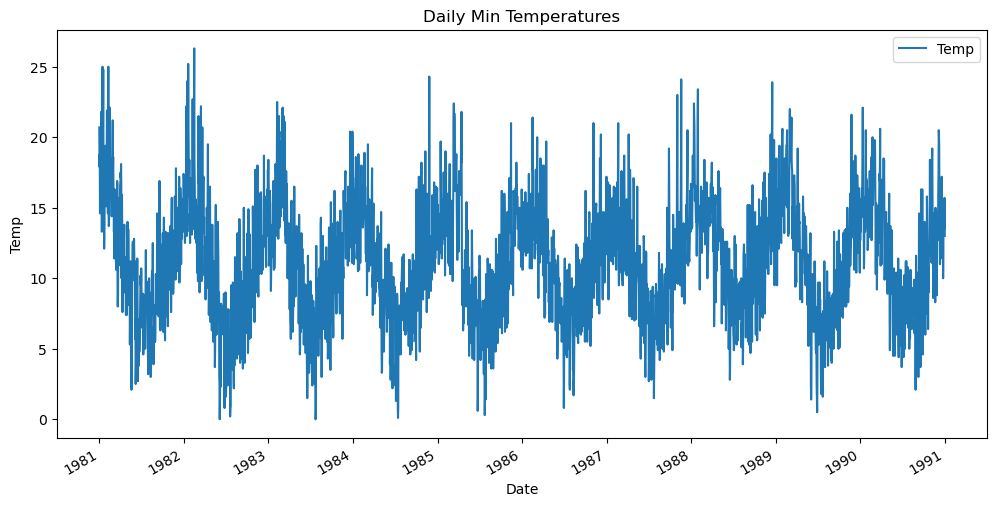

In [24]:
# Code tại đây

df.plot(figsize=(12, 6), title="Daily Min Temperatures")
plt.xlabel("Date"); plt.ylabel("Temp"); plt.show()

### 2. Vẽ rolling mean (window=12) và rolling std


Date
1981-01-01          NaN
1981-01-02          NaN
1981-01-03          NaN
1981-01-04          NaN
1981-01-05          NaN
                ...    
1990-12-27    13.875000
1990-12-28    13.875000
1990-12-29    13.841667
1990-12-30    13.716667
1990-12-31    13.575000
Name: Temp, Length: 3650, dtype: float64
Date
1981-01-01         NaN
1981-01-02         NaN
1981-01-03         NaN
1981-01-04         NaN
1981-01-05         NaN
                ...   
1990-12-27    1.697659
1990-12-28    1.697659
1990-12-29    1.701047
1990-12-30    1.471445
1990-12-31    1.449843
Name: Temp, Length: 3650, dtype: float64


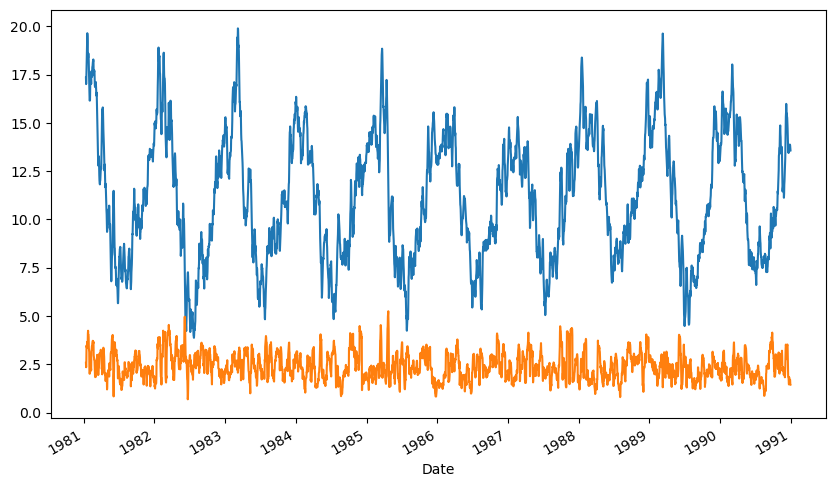

In [25]:
# Code tại đây
plt.figure(figsize=(10, 6))

# Rolling mean is a method calculate avarage a set of value in over a period of time
# Window=12 -> 12 Tháng
rolling_mean = df['Temp'].rolling(window=12).mean()
print(rolling_mean)
rolling_mean.plot()

# Std: Độ lệch chuẩn
rolling_std = df['Temp'].rolling(window=12).std()
print(rolling_std)
rolling_std.plot()

plt.show()

### 3. Vẽ seasonal plot theo tháng (đối với dữ liệu theo tháng)


In [26]:
# Code tại đây
additive = seasonal_decompose(df, model='additive', period=356)

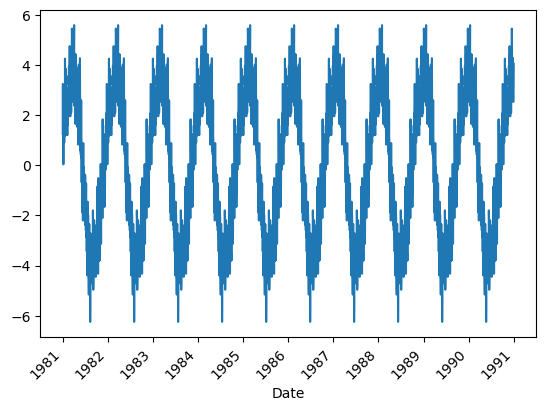

In [27]:
additive.seasonal.plot()
plt.xticks(rotation=45, fontsize=10)
plt.show()

### 4. Vẽ heatmap seasonality (month × year)


In [28]:
df_heatmap = df.copy()
df_heatmap['Year'] = df_heatmap.index.year
df_heatmap['Month'] = df_heatmap.index.month

df_heatmap_pivot = pd.pivot_table(df, values="Temp", index=df_heatmap['Month'], columns=df_heatmap['Year'], aggfunc='mean')

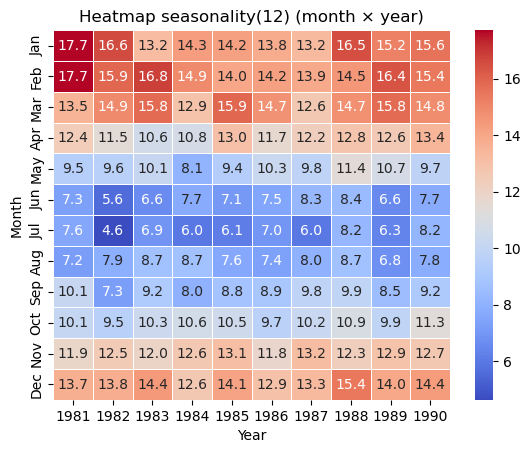

In [29]:
list_month = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

plt.Figure(figsize=(12,6))

sns.heatmap(df_heatmap_pivot,
            cmap='coolwarm',
            yticklabels = list_month,
            fmt=".1f",
            linewidth=.5,
            annot=True)
plt.title("Heatmap seasonality(12) (month × year)")

plt.show()

### 5. Kết luận: Xu hướng chung, các mùa vụ nổi bật, bất thường (nếu có)

Xu hướng chung theo từng các năm, kết luận dựa trên trung bình nhiệt độ từng tháng

Trong khoảng từ tháng 1 đến tháng 3, nhiệt độ trung bình dao động từ 14 -> 18 độ


Tháng 4 bắt đầu trở lại và đến Tháng 10: 6 -> 13 độ

Tháng 11 trở đi bắt đầu ấm dần trở lại dao động khoảng 11 -> 15 độ


Có thể thấy nhiệt độ theo chu kỳ 12 tháng, không có sự thay đổi lớn qua từng các năm, có thể chỉ chênh nhau 1 -> 3 độ